In [19]:
from fredapi import Fred
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [20]:
f = Fred(api_key = 'd099e8a4f1b849feb319c554d18cb172')

# Retrieve the raw data from FRED
series = f.get_series('UNRATE', observation_start='2006-1-1', frequency = 'm')

# Convert the series to a DataFrame
df = series.to_frame(name='UNRATE')
df.reset_index(inplace=True)
df.rename(columns={'index': 'date'}, inplace=True)
df

,date,UNRATE
0,2006-01-01,4.7
1,2006-02-01,4.8
2,2006-03-01,4.7
3,2006-04-01,4.7
4,2006-05-01,4.6
...,...,...
217,2024-02-01,3.9
218,2024-03-01,3.8
219,2024-04-01,3.9
220,2024-05-01,4.0


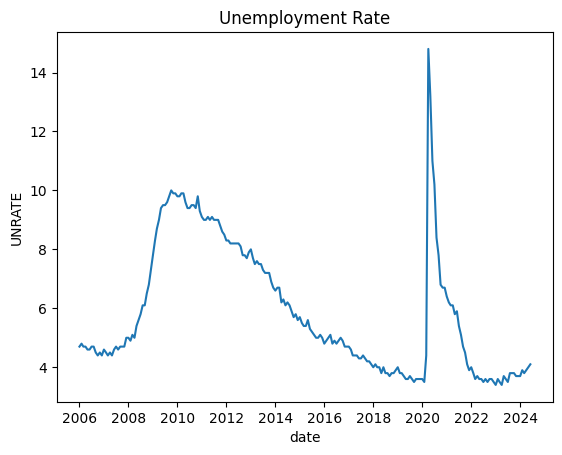

In [21]:
sns.lineplot(x = "date", y = "UNRATE", data = df, errorbar=None)
plt.title("Unemployment Rate")
plt.show()

In [22]:
df2 = f.get_series_first_release('UNRATE')
df2 = df2.to_frame(name='UNRATE_FIRST_RELEASE')
df2.reset_index(inplace=True)
df2.rename(columns={'index': 'date'}, inplace=True)

# use merge to combine the 2 DataFrames
combine = pd.merge(df, df2, on='date', how='inner')
combine.columns = ['date', 'revised', 'unrevised']
combine

c:\Users\agung\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\indexes\base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


,date,revised,unrevised
0,2006-01-01,4.7,4.7
1,2006-02-01,4.8,4.8
2,2006-03-01,4.7,4.7
3,2006-04-01,4.7,4.7
4,2006-05-01,4.6,4.6
...,...,...,...
217,2024-02-01,3.9,3.9
218,2024-03-01,3.8,3.8
219,2024-04-01,3.9,3.9
220,2024-05-01,4.0,4.0


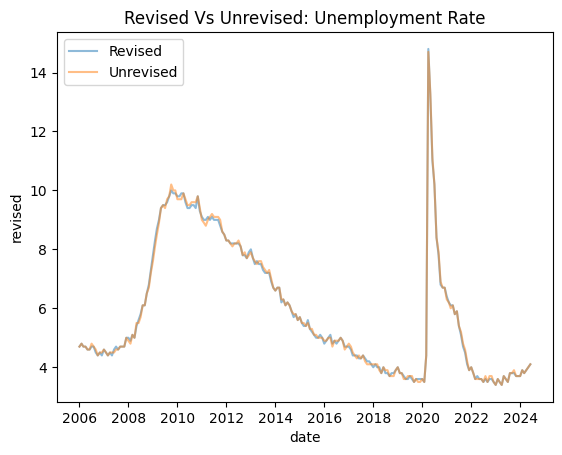

In [23]:
sns.lineplot(x = "date", 
             y = "revised", 
             data = combine, 
             errorbar=None, 
             alpha = 0.5, 
             label='Revised')

sns.lineplot(x = "date", 
             y = "unrevised", 
             data = combine, 
             errorbar=None, 
             alpha = 0.5, 
             label='Unrevised')

plt.title("Revised Vs Unrevised: Unemployment Rate")
plt.legend()
plt.show()

In [24]:
f.search("Indonesia GDP")

,id,realtime_start,realtime_end,title,observation_start,observation_end,frequency,frequency_short,units,units_short,seasonal_adjustment,seasonal_adjustment_short,last_updated,popularity,notes
series id,,,,,,,,,,,,,,,
NGDPRSAXDCIDQ,NGDPRSAXDCIDQ,2024-07-31,2024-07-31,Real Gross Domestic Product for Indonesia,2000-01-01,2023-07-01,Quarterly,Q,Domestic Currency,Domestic Currency,Seasonally Adjusted,SA,2023-11-20 07:54:03-06:00,37,None
NGDPRNSAXDCIDQ,NGDPRNSAXDCIDQ,2024-07-31,2024-07-31,Real Gross Domestic Product for Indonesia,2008-01-01,2023-07-01,Quarterly,Q,Domestic Currency,Domestic Currency,Not Seasonally Adjusted,NSA,2023-11-20 07:54:05-06:00,7,None
NGDPRXDCIDA,NGDPRXDCIDA,2024-07-31,2024-07-31,Real Gross Domestic Product for Indonesia,2008-01-01,2022-01-01,Annual,A,Domestic Currency,Domestic Currency,Not Seasonally Adjusted,NSA,2023-04-26 11:20:23-05:00,4,None
NGDPSAXDCIDQ,NGDPSAXDCIDQ,2024-07-31,2024-07-31,Nominal Gross Domestic Product for Indonesia,1990-01-01,2023-07-01,Quarterly,Q,Domestic Currency,Domestic Currency,Seasonally Adjusted,SA,2023-11-20 07:54:05-06:00,11,None
NGDPXDCIDA,NGDPXDCIDA,2024-07-31,2024-07-31,Nominal Gross Domestic Product for Indonesia,2008-01-01,2022-01-01,Annual,A,Domestic Currency,Domestic Currency,Not Seasonally Adjusted,NSA,2023-04-26 11:21:26-05:00,2,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAJOR5ASIARECM,MAJOR5ASIARECM,2024-07-31,2024-07-31,OECD based Recession Indicators for Major 5 As...,1978-01-01,2022-08-01,Monthly,M,+1 or 0,+1 or 0,Not Seasonally Adjusted,NSA,2022-12-09 14:52:24-06:00,1,This time series is an interpretation of Organ...
MAJOR5ASIARECDP,MAJOR5ASIARECDP,2024-07-31,2024-07-31,OECD based Recession Indicators for Major 5 As...,1978-01-01,2022-08-31,"Daily, 7-Day",D,+1 or 0,+1 or 0,Not Seasonally Adjusted,NSA,2022-12-09 14:47:04-06:00,1,This time series is an interpretation of Organ...
OECDNMERECDP,OECDNMERECDP,2024-07-31,2024-07-31,OECD based Recession Indicators for OECD and N...,1960-02-01,2022-02-28,"Daily, 7-Day",D,+1 or 0,+1 or 0,Not Seasonally Adjusted,NSA,2022-12-09 14:45:02-06:00,1,This time series is an interpretation of Organ...


GET_SERIES

In [27]:
gdp_data = f.get_series('GDP')
print(gdp_data)

1946-01-01          NaN
1946-04-01          NaN
1946-07-01          NaN
1946-10-01          NaN
1947-01-01      243.164
                ...    
2023-04-01    27063.012
2023-07-01    27610.128
2023-10-01    27956.998
2024-01-01    28269.174
2024-04-01    28629.153
Length: 314, dtype: float64


GET_SERIES_INFO

In [28]:
series_info = f.get_series_info('GDP')
print(series_info)

id                                                                         GDP
realtime_start                                                      2024-07-31
realtime_end                                                        2024-07-31
title                                                   Gross Domestic Product
observation_start                                                   1947-01-01
observation_end                                                     2024-04-01
frequency                                                            Quarterly
frequency_short                                                              Q
units                                                      Billions of Dollars
units_short                                                          Bil. of $
seasonal_adjustment                            Seasonally Adjusted Annual Rate
seasonal_adjustment_short                                                 SAAR
last_updated                                        

GET_SERIES_RELEASE

In [30]:
search_results = f.search('GDP')
print(search_results)

                                      id realtime_start realtime_end  \
series id                                                              
GFDEGDQ188S                  GFDEGDQ188S     2024-07-31   2024-07-31   
FYFSGDA188S                  FYFSGDA188S     2024-07-31   2024-07-31   
FYFSDFYGDP                    FYFSDFYGDP     2024-07-31   2024-07-31   
GFDGDPA188S                  GFDGDPA188S     2024-07-31   2024-07-31   
GDP                                  GDP     2024-07-31   2024-07-31   
...                                  ...            ...          ...   
OECDLORSGPORIXOBSAM  OECDLORSGPORIXOBSAM     2024-07-31   2024-07-31   
NAEXKP02GBA661S          NAEXKP02GBA661S     2024-07-31   2024-07-31   
DEBTTLESA188A              DEBTTLESA188A     2024-07-31   2024-07-31   
DEBTTLCHA188A              DEBTTLCHA188A     2024-07-31   2024-07-31   
NGMP17140                      NGMP17140     2024-07-31   2024-07-31   

                                                               